In [31]:
from dotenv import load_dotenv
load_dotenv()

True

In [32]:
from state import BlogState
from agent import get_llm , researcher_agent 

In [33]:
llm= get_llm()

In [34]:
outline = researcher_agent(llm=llm ,topic="What is LLM" ,audience="developers")

In [35]:
print(outline)

## Research Outline: “What is an LLM?” – For Developers  
*(Draft – first attempt)*  

---

### 1. Introduction  
- **Purpose of the article** – Explain Large Language Models (LLMs) in a developer‑friendly way.  
- **Why it matters** – LLMs are reshaping software development, product features, and research.  
- **Scope** – Focus on technical fundamentals, architecture, training, and practical usage.

---

### 2. Definition & Core Concepts  
| Concept | Quick Definition | Why It Matters for Devs |
|---------|------------------|------------------------|
| **Large Language Model (LLM)** | A neural network trained on massive text corpora to predict next tokens or generate text. | Forms the backbone of modern NLP APIs. |
| **Transformer architecture** | Self‑attention mechanism enabling parallel processing of tokens. | Enables scaling to billions of parameters. |
| **Pre‑training vs. Fine‑tuning** | Pre‑training learns general language; fine‑tuning adapts to specific tasks. | Guides how to 

In [36]:
from graph import build_blog_graph
from langgraph.types import Command


In [37]:
graph = build_blog_graph()

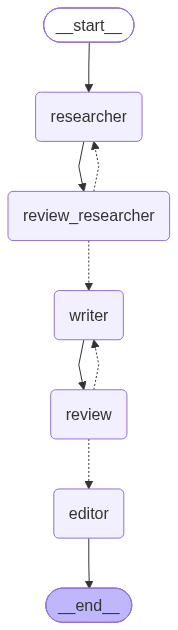

In [38]:
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [39]:
config = {
    "configurable": {
        "thread_id": "blog-1"
    }
}


In [40]:

state = graph.invoke(
    {
        "topics": "What is MCP (Model Context Protocol)?",
        "audience": "AI and Agentic AI developers"
    },
    config=config
)

In [41]:
snap = graph.get_state(config)

In [42]:
interupt_payload = snap.interrupts[0].value

In [43]:
interupt_payload

{'stage': 'researcher_review',
 'research': '## Research Outline: **Model Context Protocol (MCP)**  \n*Target Audience: AI & Agentic‑AI Developers*  \n\n---\n\n### 1. Executive Summary  \n- **What MCP is** – A lightweight, JSON‑based protocol that lets developers inject, retrieve, and persist *structured context* across multiple LLM calls.  \n- **Why it matters** – Enables true “memory” and dynamic context management without bloating prompt tokens, crucial for building scalable, multi‑agent systems.',
 'instruction': 'Reply with approve to continue writing, or describe what to change to send it back to researcher.'}

In [44]:
print("stage:",interupt_payload.get("stage"))
print("\n\n:","researcher outline \n")
print(interupt_payload.get("research"))

stage: researcher_review


: researcher outline 

## Research Outline: **Model Context Protocol (MCP)**  
*Target Audience: AI & Agentic‑AI Developers*  

---

### 1. Executive Summary  
- **What MCP is** – A lightweight, JSON‑based protocol that lets developers inject, retrieve, and persist *structured context* across multiple LLM calls.  
- **Why it matters** – Enables true “memory” and dynamic context management without bloating prompt tokens, crucial for building scalable, multi‑agent systems.


In [45]:
state= graph.invoke(
    Command(resume={"action":"approve","feedback":""}),
    config=config
)

KeyError: 'Writen'

In [46]:
# Draft review: approve, or send feedback, e.g.
# Command(resume={"action": "revise", "feedback": "Add a code example"})
snap = graph.get_state(config)
interupt_payload = snap.interrupts[0].value
print("stage:", interupt_payload["stage"])
print()
print(interupt_payload["draft"])

stage: researcher_review



KeyError: 'draft'

In [47]:
state = graph.invoke(
    Command(resume={"action": "approve", "feedback": ""}),
    config=config
)

In [48]:
# Publish step: shows the edited blog
snap = graph.get_state(config)
interupt_payload = snap.interrupts[0].value
print("stage:", interupt_payload["stage"])
print()
print(interupt_payload["final_blog"])

IndexError: tuple index out of range

In [49]:
state = graph.invoke(Command(resume={"action": "yes"}), config=config)
print("published:", state["published"])

KeyError: 'published'